# Week 4 - Logistic Regression and Feature Scaling

**Dataset:** Diabetes 130-US Hospitals dataset

**Week 4 Goal:** Apply logistic regression and feature scaling to determine whether selected hospital-utilization variables can help identify patients who are readmitted within 30 days.

The overall project examines diabetes-related outcomes using two healthcare datasets. In Weeks 1 and 3, the BRFSS health dataset was used to study BMI with regression methods. Week 2 used the hospital dataset with "time_in_hospital" as a continuous outcome. Week 4 I return to the hospital dataset and use "readmitted_30" as a binary classification target.

This week is especially important because logistic regression is designed for a binary outcome. I also examine feature scaling because the selected hospital predictors are measured on very different numerical scales. The main question is whether these hospital-utilization variables can distinguish patients who are readmitted within 30 days from those who are not.

In [53]:
# ============================================================
# 1. Import Libraries
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)   


In [54]:
# ============================================================
# 2. Load Hospital Dataset
# ============================================================

hospital_url = "https://raw.githubusercontent.com/jeganart/hospitaldatasetmilestone3/refs/heads/main/diabetic_data.csv"

hospital_df = pd.read_csv(hospital_url)

print("Dataset Shape:", hospital_df.shape)

print("\nFirst 5 Rows:")
display(hospital_df.head())

#print("~" * 80)

Dataset Shape: (101766, 50)

First 5 Rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [55]:
# ============================================================
# 3. Clean Dataset
# ============================================================

# Replace ? with missing values
hospital_df = hospital_df.replace("?", np.nan)

print("Dataset Shape:", hospital_df.shape)

print("~" * 80)

print("Missing Values:")
display(
    hospital_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("~" * 80)

Dataset Shape: (101766, 50)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Missing Values:


weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
encounter_id             0
troglitazone             0
tolbutamide              0
pioglitazone             0
rosiglitazone            0
acarbose                 0
dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [56]:
# ============================================================
# 4. Examine Readmission Variable
# ============================================================

print("Readmission Counts:")
display(
    hospital_df["readmitted"].value_counts()
)
print("~" * 80)
print("Readmission Percentages:")
display(
    (
        hospital_df["readmitted"]
        .value_counts(normalize=True) * 100
    ).round(2)
)
print("~" * 80)

Readmission Counts:


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Readmission Percentages:


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


For logistic regression let's create binary target
1 = readmitted in less than 30 days
 0 = otherwise ( not admitted or after 30 days)

30-Day Readmission Counts:


readmitted_30
0    90409
1    11357
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
30-Day Readmission Percentages:


readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


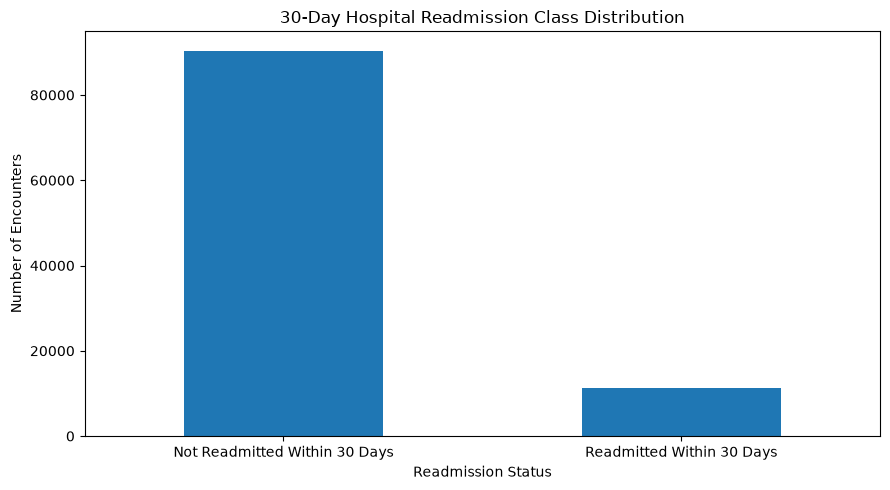

In [57]:
# ============================================================
# 5. Create Binary Target Variable
# ============================================================

hospital_df["readmitted_30"] = (
    hospital_df["readmitted"] == "<30"
).astype(int)

print("30-Day Readmission Counts:")

display(
    hospital_df["readmitted_30"].value_counts()
)

print("~" * 80)

print("30-Day Readmission Percentages:")

display(
    (
        hospital_df["readmitted_30"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

print("~" * 80)

# ============================================================
# Readmission Class Distribution
# ============================================================

readmission_counts = (
    hospital_df["readmitted_30"]
    .value_counts()
    .sort_index()
)

readmission_counts.index = [
    "Not Readmitted Within 30 Days",
    "Readmitted Within 30 Days"
]

plt.figure(figsize=(9, 5))

readmission_counts.plot(
    kind="bar"
)
plt.title(
    "30-Day Hospital Readmission Class Distribution"
)
plt.xlabel(
    "Readmission Status"
)
plt.ylabel(
    "Number of Encounters"
)
plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

clearly this is an imbalanced dataset as admitted percentage is 11.16% compared to the otherwise 88.84%

In [58]:
# ============================================================
# 6. Select Numerical Predictors from the dataset, for the 699 
# exercise I used only four predictors, but for this exercise 
# I will use 8 numerical predictors in the dataset.
# ============================================================

features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

X = hospital_df[features].copy()

y = hospital_df["readmitted_30"].copy()

print("Selected Numerical Predictors:")

for feature in features:
    print(feature)

print("~" * 150)

print("Predictor Data:")
display(X.head())

print("~" * 150)

Selected Numerical Predictors:
time_in_hospital
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
number_diagnoses
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Predictor Data:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,1,41,0,1,0,0,0,1
1,3,59,0,18,0,0,0,9
2,2,11,5,13,2,0,1,6
3,2,44,1,16,0,0,0,7
4,1,51,0,8,0,0,0,5


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00
mean,4.40,43.10,1.34,16.02,0.37,0.20,0.64,7.42
std,2.99,19.67,1.71,8.13,1.27,0.93,1.26,1.93
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Missing Values:


time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
number_diagnoses      0
dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


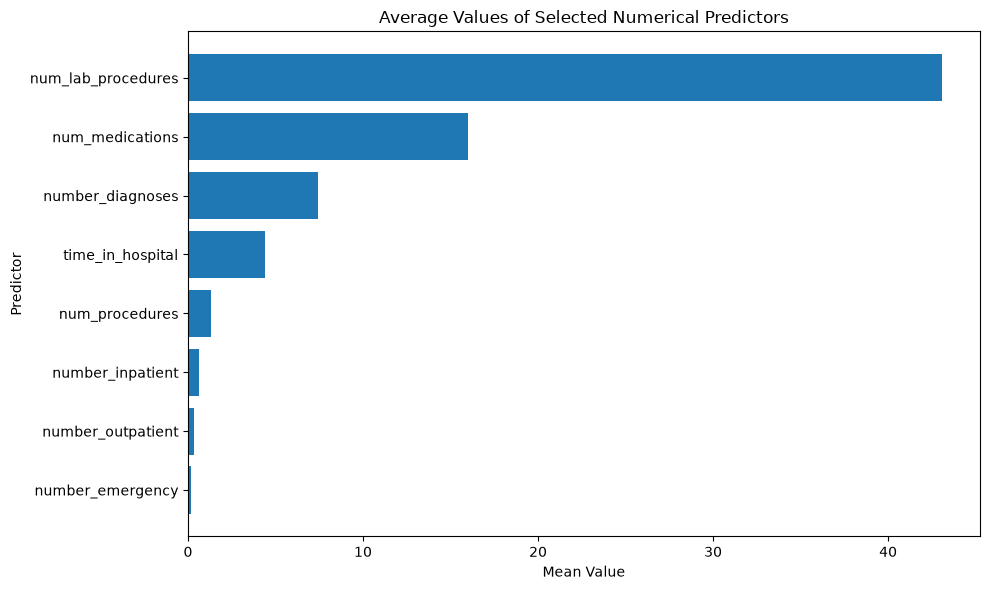

In [59]:
# ============================================================
# 7. Explore Numerical Predictors
# ============================================================

display(
    X.describe().round(2)
)
print("~" * 80)
print("Missing Values:")
display(
    X.isnull().sum()
)
print("~" * 80)
# ============================================================
#  Average Magnitude of Numerical Predictors
# ============================================================

feature_means = (
    X.mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_means.index,
    feature_means.values
)

plt.title(
    "Average Values of Selected Numerical Predictors"
)
plt.xlabel(
    "Mean Value"
)
plt.ylabel(
    "Predictor"
)
plt.tight_layout()
plt.show()

The eight numerical predictors operate on subtantially different scales, for example the average number of laboratory procedures is approximately 43.10, while the average number of emergency visits is approximately 0.20 an the average number of inpatient visits is approximately 0.64, standardization will place the predictors on a common scale before logistic regression and also makes their fitted coefficients more directly comparable in standardized units.

In [60]:
# ============================================================
# 8. Train-Test Split, use stratify to ensure that the target 
# variable is represented in both the training and testing datasets.
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("~" * 80)

Training Data Shape: (81412, 8)
Testing Data Shape: (20354, 8)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


## Logistic Regression Before Feature Scaling

Before standardizing the predictors, I first fit a logistic regression model using the original numerical values. This provides a baseline that can be compared with the scaled model. The same training and testing observations are used for both models so that the comparison is consistent.


In [61]:
# ============================================================
# 9. Logistic Regression Before Feature Scaling
# ============================================================

unscaled_model = LogisticRegression(
    max_iter=1000
)

unscaled_model.fit(
    X_train,
    y_train
)

unscaled_pred = unscaled_model.predict(
    X_test
)

unscaled_probability = unscaled_model.predict_proba(
    X_test
)[:, 1]

print("Unscaled Logistic Regression Completed.")

# ============================================================
# 10. Evaluate Unscaled Logistic Regression
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

unscaled_accuracy = accuracy_score(y_test,unscaled_pred)

unscaled_precision = precision_score(y_test,unscaled_pred,zero_division=0)

unscaled_recall = recall_score(y_test,unscaled_pred,zero_division=0)

unscaled_f1 = f1_score(y_test,unscaled_pred,zero_division=0)

unscaled_auc = roc_auc_score(y_test,unscaled_probability)

print("Unscaled Logistic Regression Results")
print("Accuracy:", round(unscaled_accuracy, 4))
print("Precision:", round(unscaled_precision, 4))
print("Recall:", round(unscaled_recall, 4))
print("F1:", round(unscaled_f1, 4))
print("ROC-AUC:", round(unscaled_auc, 4))   

Unscaled Logistic Regression Completed.
Unscaled Logistic Regression Results
Accuracy: 0.8884
Precision: 0.5
Recall: 0.0145
F1: 0.0282
ROC-AUC: 0.6357


## Feature Scaling

The selected predictors have noticeably different numerical ranges. For example, laboratory procedures and medications have much larger average values than emergency or inpatient visit counts. I therefore use StandardScaler after the train-test split. The scaler is fit only on the training data and the same transformation is applied to the test data. This avoids using information from the test set when estimating the scaling parameters.


In [62]:
# ============================================================
# 9. Feature Scaling - Standardization
# ============================================================

scaler = StandardScaler() # as we saw the predictors have different scales, so we will standardize them.

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("First 5 Rows Before Standardization:")
display(
    X_train.head()
)
print("~" * 150)
print("First 5 Rows After Standardization:")

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=features
)

display(
    scaled_df.head()
)
print("~" * 150)

# ============================================================
# 10. Verify Standardization
# ============================================================

print("Mean After Standardization:")
display(
    scaled_df.mean().round(3)
)
print("~" * 80)
print("Standard Deviation After Standardization:")
display(
    scaled_df.std().round(3)
)
print("~" * 80)

First 5 Rows Before Standardization:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
46943,11,45,1,18,0,0,0,9
60886,1,32,4,15,2,0,0,5
34417,5,46,2,16,0,0,0,5
57371,1,36,0,11,0,0,0,4
19626,10,54,3,16,0,0,0,7


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
First 5 Rows After Standardization:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,2.211912,0.096863,-0.198173,0.243726,-0.291734,-0.207009,-0.50194,0.816428
1,-1.135963,-0.563264,1.563785,-0.125745,1.285124,-0.207009,-0.50194,-1.253954
2,0.203187,0.147642,0.389146,-0.002588,-0.291734,-0.207009,-0.50194,-1.253954
3,-1.135963,-0.360148,-0.785492,-0.618374,-0.291734,-0.207009,-0.50194,-1.771549
4,1.877125,0.553874,0.976466,-0.002588,-0.291734,-0.207009,-0.50194,-0.218763


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Mean After Standardization:


time_in_hospital      0.0
num_lab_procedures   -0.0
num_procedures        0.0
num_medications       0.0
number_outpatient     0.0
number_emergency      0.0
number_inpatient     -0.0
number_diagnoses      0.0
dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Standard Deviation After Standardization:


time_in_hospital      1.0
num_lab_procedures    1.0
num_procedures        1.0
num_medications       1.0
number_outpatient     1.0
number_emergency      1.0
number_inpatient      1.0
number_diagnoses      1.0
dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


### After applying StandardScaler, all eight predictors have means approximately equal to 0 and standard deviations approximately equal to 1. This confirms that standardization was performed correctly, because now the predictors expressed in standardized units, the logistic regression coefficients can subsequently be compared in terms of approximately one-standard-deviation changes.

In [63]:
# ============================================================
# 11. Logistic Regression
# ============================================================

log_model = LogisticRegression(
    max_iter=1000
)

log_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression Model Completed.")

print("~" * 80)

Logistic Regression Model Completed.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [64]:
# ==============================================================================
# 12. Make Predictions
# The predict () returns the predicted class of 0 or 1, 
# while the predict_proba () returns estimated probability of 30-day readmission.
# ===============================================================================

y_pred = log_model.predict(
    X_test_scaled
)

y_probability = log_model.predict_proba(
    X_test_scaled
)[:, 1]

print("First 10 Predicted Classes:")
print(y_pred[:10])

print()
print("~" * 80)
print("First 10 Predicted Probabilities:")
print(
    y_probability[:10]
)

print("~" * 80)

First 10 Predicted Classes:
[0 0 0 0 0 0 0 0 0 0]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
First 10 Predicted Probabilities:
[0.12606709 0.08938551 0.10401519 0.13298433 0.11626062 0.08168732
 0.07646415 0.07423178 0.28302741 0.1614616 ]
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


Accuracy: 0.8884
ROC-AUC: 0.6357

Confusion Matrix:
[[18050    33]
 [ 2238    33]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.50      0.01      0.03      2271

    accuracy                           0.89     20354
   macro avg       0.69      0.51      0.48     20354
weighted avg       0.85      0.89      0.84     20354



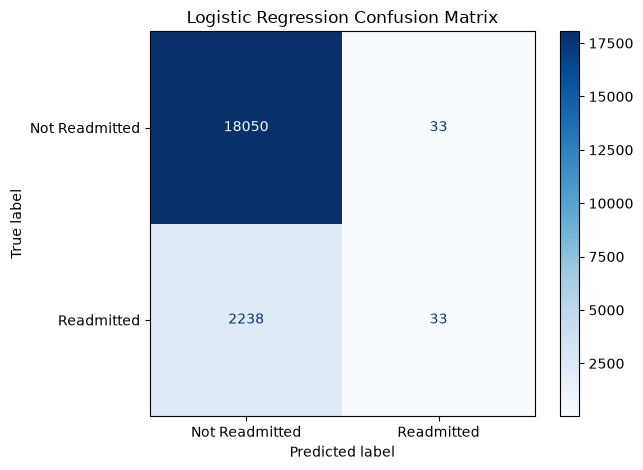

In [65]:
# ============================================================
# 13. Model Evaluation
# ============================================================


accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_probability)

print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Readmitted", "Readmitted"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


### Impression 
### The 88.84% accuracy looks strong but the model is doing a poor job in identifying patients who are re-admitted within 30 days. The target is also clearly imbalanced with Class 0 has 18083 patients and Class 1 2271 patients, so roughly 89% of test observations are class 0, so the model achieves high accuracy largely by predicting almost everyone as not readmitted Looking at the confusion matrix, the model correctly identified 18050 non-readmitted patients, but correctly identified only 33 of 2271 patients who were readmitted within 30 days.

### The class 1 recall of 0.01 is the biggest concern, that indicates the mdoel detects only 1% of the actual 30-day readmissions.

### The ROC-AUC of 0.6357 provides an important contrast. Although the model preforms poorly when classifications are made at the default 0.50 threshold, its predicted probabilities still contain some ability to rank patients according to readmission risk. This suggests that the problem is partly related to the decision threshold and severe class imbalance, rather than the model containing no predictive information at all.

In [66]:
# ============================================================
# 14. Logistic Regression Coefficients
# ============================================================

coefficient_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": log_model.coef_[0]
})

coefficient_df["Odds_Ratio"] = np.exp(
    coefficient_df["Coefficient"]
)

coefficient_df["Absolute_Coefficient"] = abs(
    coefficient_df["Coefficient"]
)

coefficient_df = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(
    coefficient_df.round(4)
)

print("~" * 80)

,Feature,Coefficient,Odds_Ratio,Absolute_Coefficient
6,number_inpatient,0.3389,1.4034,0.3389
7,number_diagnoses,0.0946,1.0992,0.0946
0,time_in_hospital,0.0713,1.0739,0.0713
3,num_medications,0.0552,1.0568,0.0552
2,num_procedures,-0.0442,0.9568,0.0442
5,number_emergency,0.0254,1.0257,0.0254
4,number_outpatient,-0.0027,0.9973,0.0027
1,num_lab_procedures,-0.0012,0.9988,0.0012


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


#### Given we standardized the predictors, the coefficient can be interpreted for approximately a one standard deviation increase in each predictor. A positive coefficient indicates higher modeleded odds of 30-day readmission, while a negative coefficient indicates lower modeled odds, holding the other included variables as constant.

#### Impression: Among the eight standardized numerical predictors, number_inpatient has the strongest association with 30 day readmission with a co-efficient of 0.3389 and odds ration of 1.4034, this indicates that a one-standard-deviation increase in prior inpatient visits was associated with approximately 40% higher modeled odds of readmission within 30 days, holding the other predictors constant. number_diagnoses, time_in_hospital and num_medications also showed positive associations with readmission. In contrast, num_procedures had a small negative coefficient, the number_outpatient and num_lab_procedures had coefficients close to 0.

,Actual_Readmission,Predicted_Readmission,Predicted_Probability
0,0,0,0.126067
1,0,0,0.089386
2,0,0,0.104015
3,1,0,0.132984
4,1,0,0.116261
5,0,0,0.081687
6,0,0,0.076464
7,0,0,0.074232
8,0,0,0.283027
9,0,0,0.161462


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


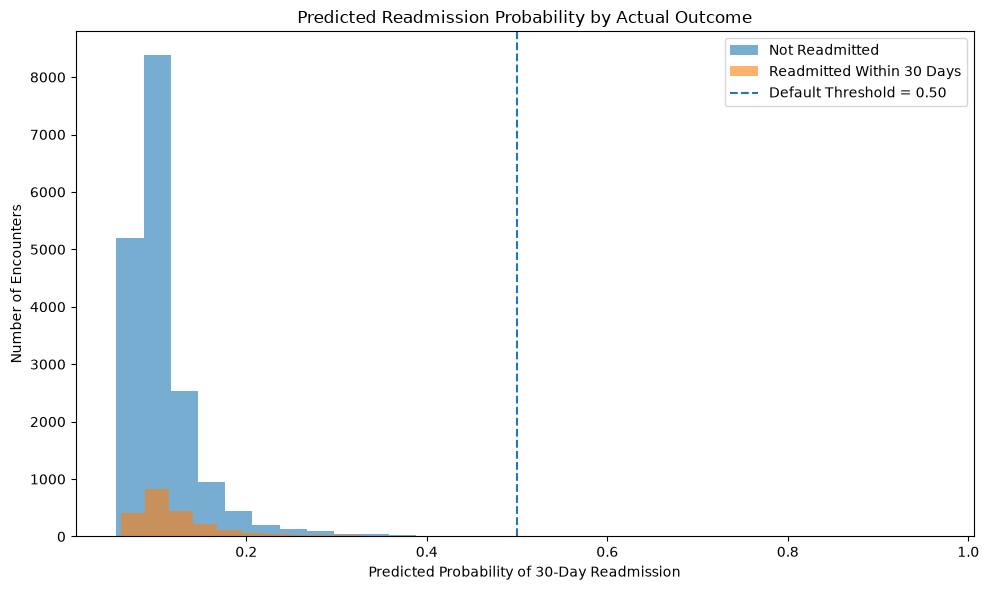

In [67]:
# ============================================================
# 15. Actual vs Predicted Results
# ============================================================

results_df = pd.DataFrame({
    "Actual_Readmission": y_test.values,
    "Predicted_Readmission": y_pred,
    "Predicted_Probability": y_probability
})

display(
    results_df.head(15)
)

print("~" * 80)

# Predicted vs Actual Readmission status

probability_df = pd.DataFrame({
    "Actual_Readmission": y_test.values,
    "Predicted_Probability": y_probability
})


not_readmitted_probability = probability_df[
    probability_df["Actual_Readmission"] == 0
]["Predicted_Probability"]


readmitted_probability = probability_df[
    probability_df["Actual_Readmission"] == 1
]["Predicted_Probability"]
plt.figure(figsize=(10, 6))

plt.hist(
    not_readmitted_probability,
    bins=30,
    alpha=0.6,
    label="Not Readmitted"
)

plt.hist(
    readmitted_probability,
    bins=30,
    alpha=0.6,
    label="Readmitted Within 30 Days"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold = 0.50"
)

plt.title(
    "Predicted Readmission Probability by Actual Outcome"
)

plt.xlabel(
    "Predicted Probability of 30-Day Readmission"
)

plt.ylabel(
    "Number of Encounters"
)
plt.legend()
plt.tight_layout()
plt.show()

### The Probability distribution help explain why the model produces so few positive classifications, Most predicted probabilities remain below the threshold of 0.50, including probabilities for many patients who were actually readmitted. Although the distribution may show some seperation between the two classes, their overlap is substantial. This is consistent with the moderate ROC-AUC of 0.6357 and extremely low class 1 recall at the default threshold.

## Compare Logistic Regression Before and After Scaling

The following table compares the unscaled and standardized logistic regression models using the same test observations. Accuracy is included, but because the positive readmission class is uncommon, precision, recall, F1, ROC-AUC, and the confusion matrix are more informative for evaluating the model.


In [68]:
# ============================================================
# Compare Unscaled and Scaled Logistic Regression
# ============================================================

scaled_precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

scaled_recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

scaled_f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression - Unscaled",
        "Logistic Regression - Standardized"
    ],
    "Accuracy": [
        unscaled_accuracy,
        accuracy
    ],
    "Precision": [
        unscaled_precision,
        scaled_precision
    ],
    "Recall": [
        unscaled_recall,
        scaled_recall
    ],
    "F1": [
        unscaled_f1,
        scaled_f1
    ],
    "ROC_AUC": [
        unscaled_auc,
        auc
    ]
})

display(
    comparison_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression - Unscaled,0.8884,0.5,0.0145,0.0282,0.6357
1,Logistic Regression - Standardized,0.8884,0.5,0.0145,0.0282,0.6357


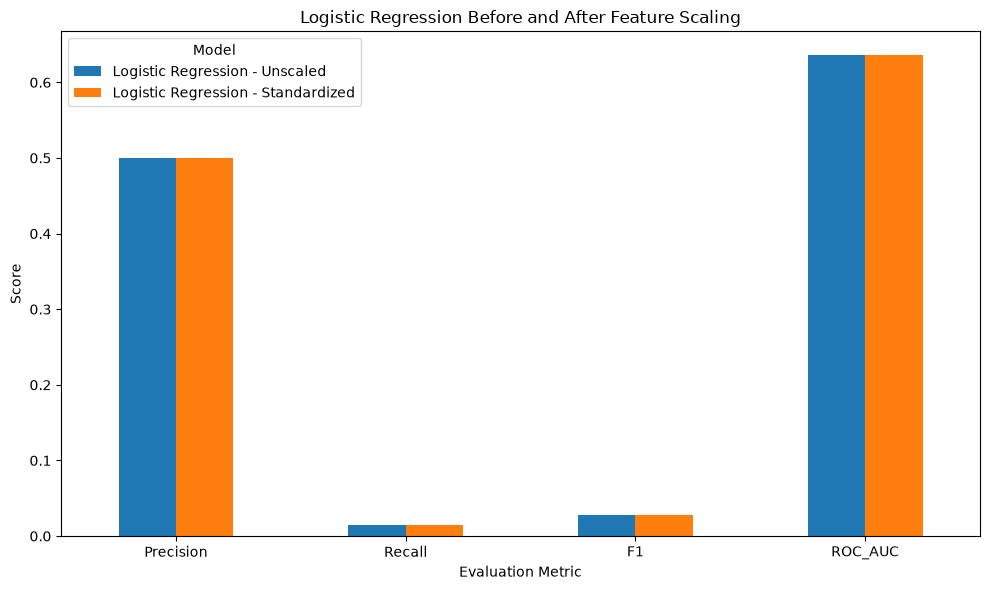

In [69]:
# ============================================================
# Visual Comparison of Classification Metrics
# ============================================================

comparison_plot = comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1", "ROC_AUC"]
]

comparison_plot.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Logistic Regression Before and After Feature Scaling"
)
plt.xlabel(
    "Evaluation Metric"
)
plt.ylabel(
    "Score"
)
plt.xticks(
    rotation=0
)
plt.legend(
    title="Model"
)
plt.tight_layout()
plt.show()

# Week 4 Summary and Interpretation

Logistic regression was used to predict 30-day hospital readmission from eight numerical hospital-utilization predictors. The binary outcome was strongly imbalanced: **11.16%** of encounters were readmitted within 30 days, while **88.84%** were not. Because of this imbalance, accuracy alone was not sufficient to judge model performance.

For the standardized logistic regression model, accuracy was **0.8884** and ROC-AUC was **0.6357**. The confusion matrix was [[18050, 33], [2238, 33]]. Although the accuracy appeared high, the model correctly identified only **33 of 2,271** actual 30-day readmissions. Class 1 recall was therefore approximately **0.01** and F1 approximately **0.03**. This shows that the model predicted the majority class very well but performed poorly at identifying the minority readmission class at the default 0.50 threshold.

Feature scaling was performed using StandardScaler. The scaler was fit only on the training predictors and the same transformation was then applied to the test predictors. After standardization, each training predictor had a mean approximately equal to 0 and a standard deviation approximately equal to 1. However, standardization did not materially change predictive performance. The unscaled and standardized logistic regression models produced the same rounded accuracy (0.8884), precision (0.5000), recall (0.0145), F1 (0.0282), and ROC-AUC (0.6357). This was an important finding because it showed that although scaling placed the predictors on a common scale and made the standardized coefficients easier to compare, it did not improve classification performance for this dataset.

Among the standardized predictors, number_inpatient had the largest absolute logistic regression coefficient (**0.3389**) and an odds ratio of approximately **1.4034**. Because the predictors were standardized, a one-standard-deviation increase in prior inpatient visits was associated with approximately **40.3% higher modeled odds** of 30-day readmission, holding the other included predictors constant. This is an association within the fitted model and should not be interpreted as a causal effect.

I used a stratified **80/20 train-test split** so that the readmission-class proportions were maintained in both sets and the final model could be evaluated on observations not used for fitting. The same split was used for the unscaled and scaled models, making their test results directly comparable. I didn't do any hyperparameter tuning; the main purpose is to understand logistic regression, feature scaling, class imbalance, and appropriate classification metrics.

I expected the hospital-utilization variables to contain some information about readmission risk, and the ROC-AUC of **0.6357** supports modest ranking ability. The most unexpected finding was that **88.84% accuracy did not represent strong classification performance**. The model missed approximately **98.5%** of actual 30-day readmissions at the default threshold. This demonstrates why recall, F1, ROC-AUC, predicted probabilities, and the confusion matrix are more informative than accuracy alone for this imbalanced healthcare outcome.